# Image audit

**Dataset:** Kaggle [`sehastrajits/fundus-aptosddridirdeyepacsmessidor`](https://www.kaggle.com/datasets/sehastrajits/fundus-aptosddridirdeyepacsmessidor), the same 45,327 files as notebook 01.

**Goal:** notebook 01 judged the files by their **names**. This notebook looks at the **pixels**: can every file be opened, how big are the images really, and is the same picture stored under different names?

**How to run:** Colab runtime (browser, or VS Code with the Colab extension), CPU is enough. Run all cells in order. You'll be asked for your Kaggle API token. Steps 2 and 3 read every image and take several minutes.

**Method:** every step states its **criteria before its results**. The criteria were written on 2026-11-20, before the first run on the real data. Values expected from notebook 01 are checked automatically (✅ / ⚠️) and listed together at the end.

**Main findings** (run of 2026-11-21)
- **Every file opens.** 15 are blank or nearly black and are excluded. This fully explains why the selection now has 20,145 base photos instead of notebook 01's 20,150.
- **The images are not all ~600 px:** EyePACS 600×600, DDR mostly 512×512, APTOS originals 358–2,848 px. ➜ Model input size at most **512 px** (D-013).
- **APTOS:** the selection used to keep the uploader's 600 px copy instead of the full-size original for 63% of Severe photos but only 7% of No DR. That is a difference a model could learn as a shortcut. ➜ The selection now always prefers the full-size original (D-007).
- **The APTOS originals themselves** are smaller for No DR (median 1,050 px) than for the other grades (1,736–1,958 px). The selection can't remove that; it is a risk to check during training (D-013).
- **135 photos are stored under two or more different names.** All are within one source (APTOS, DDR, Messidor-1, IDRiD). **31 of them carry different grades**, 30 of those in APTOS's own official labels.
- ➜ Duplicate policy (D-012). Preview: 167 photos removed, base dataset **19,978**. It is applied after the near-copy check (D-014).

Decisions: D-012 to D-014 in `notes/decision_log.md`

## Step 1 · Set up, download and index

### 1a. Libraries and shared code
Imports the libraries, creates a temporary folder on the Colab runtime, and clones the repo from GitHub to get the shared code in `src/`. The runtime can't see your laptop, so **push `src/` changes before running**. Until PR #5 is merged, the code comes from branch `5-data-audit`.

In [1]:
import os, io, sys, hashlib, subprocess
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, ImageOps
from tqdm.auto import tqdm

SEED = 42
PROJECT_DIR = '/content/DR_project'          # temporary: deleted when the session ends
os.makedirs(PROJECT_DIR, exist_ok=True)

REPO = 'diabetic-retinopathy-classification-system'
BRANCH = '5-data-audit'                      # change to 'main' once PR #5 is merged
REPO_DIR = f'/content/{REPO}'
if os.path.isdir(REPO_DIR):                  # re-running: fetch newly pushed changes
    subprocess.run(['git', '-C', REPO_DIR, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', '-b', BRANCH,
                    f'https://github.com/DL-Disease-Classification/{REPO}.git', REPO_DIR], check=True)
sys.path.insert(0, REPO_DIR)
from src.dataset_index import build_index, CLASS_NAMES
from src.selection import add_look_stats, select_clean_photos

commit = subprocess.run(['git', '-C', REPO_DIR, 'rev-parse', '--short', 'HEAD'],
                        capture_output=True, text=True).stdout.strip()
print(f'Shared code: branch {BRANCH}, commit {commit}')

Shared code: branch 5-data-audit, commit b3359b1


### 1b. Download the dataset
Same as notebook 01. The token comes from Colab Secrets in the browser. In VS Code, Secrets may not work, so a password box asks for it. The token is never saved in the notebook.

In [2]:
!pip install -q -U kagglehub
import kagglehub

try:   # works in the Colab browser tab
    from google.colab import userdata
    os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
except Exception:   # VS Code: secrets may be unavailable, so ask for the token instead
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste your Kaggle API token: ')

DATA_ROOT = kagglehub.dataset_download('sehastrajits/fundus-aptosddridirdeyepacsmessidor')
print('Dataset downloaded to:', DATA_ROOT)

100%|██████████| 10.1G/10.1G [01:45<00:00, 103MB/s] 

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/sehastrajits/fundus-aptosddridirdeyepacsmessidor/versions/1


### 1c. Index every file
`build_index` from `src/` gives one row per file and decodes its name. This was the first time the `src/` code ran on the full dataset, so we check that it reproduces notebook 01: **45,327 files** (the notebook stops if not) and **24,916 photos**. Notebook 01 used `nnn-nnnn` as the DDR photo ID, while `src/` uses the full `nnn-nnnn-nnn` name, so the cell also lists any DDR ID that two full names share.

**Result:** ✅ 45,327 files and 24,916 photos. No DDR ID is shared, so the switch to full DDR names changes nothing.

In [3]:
# Values expected from notebook 01 (Steps 4, 5c and 10), checked throughout this notebook
EXPECTED = {'files': 45_327, 'photos': 24_916, 'base': 20_150, 'family_B': 3_605, 'idrid_conflicts': 22}
CHECKS = []

def check(name, got, expected, stop=False):
    ok = got == expected
    CHECKS.append({'check': name, 'got': got, 'expected': expected, 'result': '✅' if ok else '⚠️'})
    print(f"{'✅' if ok else '⚠️'} {name}: {got:,} (expected {expected:,})")
    if stop and not ok:
        raise RuntimeError(f'{name} differs from notebook 01: stop and investigate before going on.')

DATA_DIR = os.path.join(DATA_ROOT, 'split_dataset')
df = build_index(DATA_DIR)
check('Files', len(df), EXPECTED['files'], stop=True)
check('Distinct photos (base_id)', df.base_id.nunique(), EXPECTED['photos'])

ddr = df[df.ddr_code.notna()]
short_id = ddr.base_id.str.rsplit('-', n=1).str[0]
shared = ddr.groupby(short_id)['base_id'].transform('nunique') > 1
print(f'\nDDR nnn-nnnn IDs shared by more than one full name: {short_id[shared].nunique():,}')
if shared.any():
    print(ddr[shared].sort_values('fname')[['split', 'label', 'fname']].head(20).to_string())

print('\nFiles per source and split\n', pd.crosstab(df.source, df.split, margins=True))

✅ Files: 45,327 (expected 45,327)
✅ Distinct photos (base_id): 24,916 (expected 24,916)

DDR nnn-nnnn IDs shared by more than one full name: 0

Files per source and split
 split       test  train   val    All
source                              
APTOS       1940   6899  1524  10363
DDR          855   2585   576   4016
EyePACS     5738  19868  4583  30189
IDRiD         39    152    42    233
Messidor-1    79    227    50    356
Messidor-2    40    109    21    170
All         8691  29840  6796  45327


## Step 2 · Can every file be opened?
Every file is opened and **fully decoded**. For each one we record its format, colour mode, width, height and file size, plus two fingerprints used in Step 5: the MD5 of the file's bytes and the MD5 of its decoded pixels. Excluded files are shown with their contrast stretched, so a dark photo becomes visible.

**Criteria (fixed before running)**
- **Unreadable:** PIL can't open the file or can't decode all of its pixels (truncated files count). ➜ Excluded.
- **Blank:** the file decodes, but the standard deviation of its pixels is below 5 (on 0–255). ➜ Excluded.

**Results**
- **0 unreadable.** 42 DDR `.jpg` files are really MPO (multi-picture JPEG); PIL reads them normally.
- **15 blank or nearly black files**, all excluded as the rule says:
  - 7 completely black `FA` copies of EyePACS photos (family D, never used);
  - 3 Gaussian-filtered APTOS files (never used);
  - 5 real EyePACS originals that are nearly black.
- The rule was written for empty images, but it also catches those 5 nearly black photos. The rule is unchanged; only its name is widened to "blank or nearly black".

Reading files:   0%|          | 0/45327 [00:00<?, ?it/s]

Unreadable files: 0

Blank or nearly black files (pixel std < 5): 15
       split  label   source                       fname  width  height  pixel_std
2090   train      0  EyePACS         20347_right-600.jpg    600     600   4.587458
6295   train      1  EyePACS      10600_right-600-FA.jpg    600     600   0.000000
7324   train      1  EyePACS       18972_left-600-FA.jpg    600     600   0.000000
11747  train      1    APTOS  cae51154e1ce-GF-600-FA.jpg    600     600   2.592301
13207  train      2  EyePACS         14915_right-600.jpg    600     600   4.075874
25188  train      4  EyePACS      16802_right-600-FA.jpg    600     600   0.000000
25225  train      4  EyePACS       17157_left-600-FA.jpg    600     600   0.000000
25229  train      4  EyePACS          17157_left-600.jpg    600     600   4.453583
26067  train      4  EyePACS      24472_right-600-FA.jpg    600     600   0.000000
29697  train      4    APTOS     e821c1b6417a-GF-600.jpg    600     600   4.160910
41154   test      

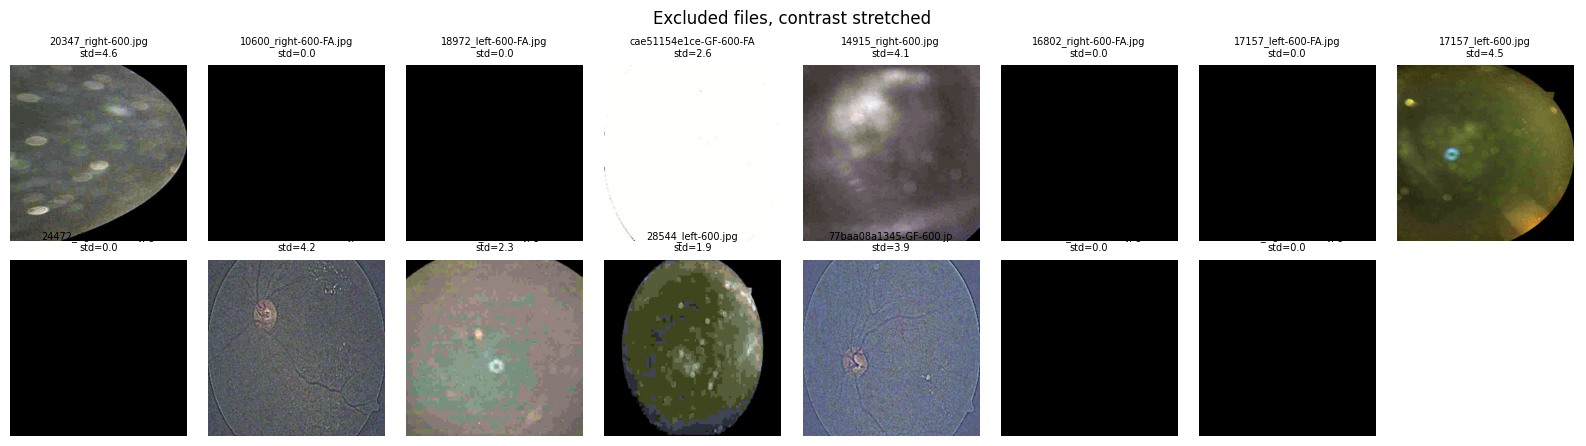


Actual format (columns) by file extension and source
format           JPEG  MPO   PNG
source     ext                  
APTOS      jpg   6701    0     0
           png      0    0  3662
DDR        jpg   3974   42     0
EyePACS    jpg  30189    0     0
IDRiD      jpg    233    0     0
Messidor-1 png      0    0   356
Messidor-2 jpg    170    0     0

Colour mode (columns) by source
mode          RGB
source           
APTOS       10363
DDR          4016
EyePACS     30189
IDRiD         233
Messidor-1    356
Messidor-2    170


In [4]:
ImageFile.LOAD_TRUNCATED_IMAGES = False      # PIL's default, set explicitly: a truncated file must raise an error

def inspect_file(path):
    # Open and fully decode one file. Returns its format, size and fingerprints, or the error.
    rec = {'path': path, 'error': ''}
    try:
        with open(path, 'rb') as f:
            data = f.read()
        rec['file_bytes'] = len(data)
        rec['md5'] = hashlib.md5(data).hexdigest()                       # same bytes
        with Image.open(io.BytesIO(data)) as im:
            rec['format'], rec['mode'] = im.format, im.mode
            rec['width'], rec['height'] = im.size
            px = np.asarray(im.convert('RGB'))                             # decodes every pixel
        rec['pixel_md5'] = f'{hashlib.md5(px.tobytes()).hexdigest()}_{px.shape[1]}x{px.shape[0]}'  # same pixels
        rec['pixel_std'] = float(px[::4, ::4].std())
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'
    return rec

with ThreadPoolExecutor(8) as ex:
    recs = list(tqdm(ex.map(inspect_file, df['path']), total=len(df), desc='Reading files'))
audit = df.merge(pd.DataFrame(recs), on='path', how='left')
audit['ext'] = audit['fname'].str.rsplit('.', n=1).str[-1].str.lower()
audit.to_csv(os.path.join(PROJECT_DIR, 'file_audit.csv'), index=False)

# --- unreadable and blank or nearly black files
bad = audit[audit.error != '']
blank = audit[(audit.error == '') & (audit.pixel_std < 5)]
print(f'Unreadable files: {len(bad)}')
if len(bad):
    print(bad[['split', 'label', 'source', 'fname', 'error']].to_string())
print(f'\nBlank or nearly black files (pixel std < 5): {len(blank)}')
print(blank[['split', 'label', 'source', 'fname', 'width', 'height', 'pixel_std']].to_string())
if len(blank):
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), blank.head(16).iterrows()):
        im = Image.open(r.path).convert('RGB'); im.thumbnail((256, 256))
        ax.imshow(ImageOps.autocontrast(im))          # contrast stretched: a dark photo becomes visible
        ax.set_title(f'{r.fname[:22]}\nstd={r.pixel_std:.1f}', fontsize=7)
    plt.suptitle('Excluded files, contrast stretched'); plt.tight_layout(); plt.show()

# --- formats
print('\nActual format (columns) by file extension and source')
print(pd.crosstab([audit.source, audit.ext], audit.format.fillna('unreadable')))
print('\nColour mode (columns) by source')
print(pd.crosstab(audit.source, audit['mode'].fillna('unreadable')))

readable = audit[(audit.error == '') & (audit.pixel_std >= 5)].copy()
readable['short_side'] = readable[['width', 'height']].min(axis=1).astype(int)
readable['long_side'] = readable[['width', 'height']].max(axis=1).astype(int)
readable['has_600'] = readable['fname'].str.contains('-600')       # the '600' marker in the name

## Step 3 · Re-run the selection, and compare it with notebook 01
Selection rule v3 (`src/selection.py`) is run on the readable files. `add_look_stats` reads every file again (fast, partial decode). Since 2026-11-23 the rule prefers a full-size original over its resized `-600` copy (Step 4, D-007). That changes which file is kept for a photo, not which photos are kept, so the counts are unaffected. The same selection is then run **without** the Step 2 exclusions. It must reproduce notebook 01 exactly, and any photo whose kept file changed is listed.

**Results**
- With the exclusions: base **20,145** (notebook 01: 20,150), family B **3,608** (3,605). ⚠️ Expected after excluding files.
- Without them: exactly **20,150** and **3,605** ✅. The exclusions explain the whole difference:
  - 3 photos fall back to a family B copy (base −3, family B +3);
  - 2 photos have no other usable file (base −2).
- Dropping the whole photo when its original is excluded was considered and rejected (D-012).

In [5]:
look = add_look_stats(readable)
clean = select_clean_photos(look)
base = clean[clean.family.isin(['original', 'A_geometry'])]
fam_b = clean[clean.family == 'B_hue']
print(f'Files excluded in Step 2: {len(bad) + len(blank)}')
check('Base dataset photos', len(base), EXPECTED['base'])
check('Family B add-on photos', len(fam_b), EXPECTED['family_B'])
clean.to_csv(os.path.join(PROJECT_DIR, 'clean_selection.csv'), index=False)

# The same selection WITHOUT the exclusions: must reproduce notebook 01
look_blank = add_look_stats(audit.loc[blank.index]) if len(blank) else look.iloc[:0]
clean_all = select_clean_photos(pd.concat([look, look_blank]))
check('Base photos if nothing were excluded', int(clean_all.family.isin(['original', 'A_geometry']).sum()),
      EXPECTED['base'])
check('Family B photos if nothing were excluded', int((clean_all.family == 'B_hue').sum()), EXPECTED['family_B'])

cmp = clean_all[['base_id', 'label', 'fname', 'family']].merge(
    clean[['base_id', 'fname', 'family']], on='base_id', how='left', suffixes=('_before', '_now'))
changed = cmp[cmp.fname_before != cmp.fname_now]
print(f'\nPhotos whose kept file changed because of the exclusions: {len(changed)}')
print(changed.to_string())

Files excluded in Step 2: 15
⚠️ Base dataset photos: 20,145 (expected 20,150)
⚠️ Family B add-on photos: 3,608 (expected 3,605)
✅ Base photos if nothing were excluded: 20,150 (expected 20,150)
✅ Family B photos if nothing were excluded: 3,605 (expected 3,605)

Photos whose kept file changed because of the exclusions: 5
           base_id  label         fname_before family_before                fname_now family_now
4889   14915_right      2  14915_right-600.jpg      original  14915_right-600-ALL.jpg      B_hue
5520    16349_left      2   16349_left-600.jpg      original                      NaN        NaN
5892    17157_left      4   17157_left-600.jpg      original   17157_left-600-HFF.jpg      B_hue
8702   20347_right      0  20347_right-600.jpg      original                      NaN        NaN
12096   28544_left      2   28544_left-600.jpg      original   28544_left-600-ALL.jpg      B_hue


## Step 4 · How big are the images?
Exact sizes per source, for every readable file and for the base dataset. `has_600` = the name contains `-600`, the marker we guessed means "resized to 600 px". The last part checks two things about APTOS. First, which file the selection keeps for each photo: the full-size original (`.png`) or the uploader's 600 px copy (`-600.jpg`). Both count as "original", because neither has an augmentation code. Second, whether the size of the **originals** differs by grade.

**Criteria (fixed before running)**
- **Size rule:** the model's input size must not exceed the shorter side of **95%** of base-dataset photos (their 5th percentile), so almost no photo is enlarged.
- **The docs' "~600 px" assumption** is confirmed only if **at least 95%** of base photos have a shorter side of **550–650 px**.
- **File kept per APTOS photo** (added 2026-11-23, after the first run showed the problem below): no APTOS photo may be kept as its 600 px copy while its full-size original is usable.

**Results**
- **EyePACS:** all 600×600.
- **APTOS:** originals (`.png`) come in 17 sizes, 358–2,848 px; the `-600` copies are all 600×600.
- **DDR:** mostly 512×512 (3,224 of 4,016 files), up to 3,456 px.
- **Messidor-1/2:** 512×512. **IDRiD:** 4288×2848.
- The `-600` marker means 600×600 for APTOS and EyePACS, but not for the 3 DDR files that carry it.
- **Base photos:** shorter side min 358, 5th percentile 512, median 600. 99.8% are at least 512 px. ➜ **Model input ≤ 512 px** (D-013).
- **"~600 px":** only 63.4% fall within 550–650 px. ➜ **Not confirmed.** The docs get the measured sizes.
- **File kept per APTOS photo.**
  - In the first run (2026-11-21), the rule kept the 600 px copy instead of the full-size original for 629 of 3,661 APTOS photos. Which file won depended only on folder order.
  - It also depended strongly on the grade: No DR 7%, Mild 24%, Moderate 15%, **Severe 63%**, PDR 47%.
  - A file type linked to the grade is a shortcut a model could learn. ➜ Rule v3 now prefers the full-size original, then the file name, and no longer depends on folder order (D-007, 2026-11-23).
- **APTOS originals by grade:**
  - Median shorter side: No DR **1,050 px**, Mild 1,736, Moderate 1,958, Severe 1,944, PDR 1,958.
  - APTOS seems to have photographed healthy and diseased eyes differently (likely different cameras or clinics).
  - The selection can't remove this. ➜ A risk to check during training: results per source, and Grad-CAM (D-013).

In [6]:
def size_table(d, by):
    rows = []
    for key, g in d.groupby(by):
        sizes = (g.width.astype(str) + '×' + g.height.astype(str)).value_counts()
        rows.append({**dict(zip(by, key if isinstance(key, tuple) else (key,))),
                     'files': len(g), 'distinct sizes': len(sizes),
                     'most common (W×H)': ', '.join(f'{s} ({n:,})' for s, n in sizes.head(3).items()),
                     'short min': g.short_side.min(), 'short p5': int(g.short_side.quantile(.05)),
                     'short median': int(g.short_side.median()), 'short max': g.short_side.max()})
    return pd.DataFrame(rows).to_string(index=False)

print('All readable files, by source and 600-marker')
print(size_table(readable, ['source', 'has_600']))
print('\nBase dataset, by source')
print(size_table(base, ['source']))

# --- criterion 1: training input size
p5 = int(base.short_side.quantile(0.05))
print(f'\nShorter side of base photos: min {base.short_side.min()}, 5th percentile {p5}, '
      f'median {int(base.short_side.median())}')
for s in (224, 300, 384, 448, 512, 600):
    print(f'  shorter side ≥ {s} px: {(base.short_side >= s).mean():.1%}')
print(f'→ Size rule: model input size at most {p5} px')

# --- criterion 2: the "~600 px" assumption
share_600 = base.short_side.between(550, 650).mean()
print(f'\n"~600 px" assumption: {share_600:.1%} of base photos have a shorter side of 550–650 px → '
      + ('CONFIRMED' if share_600 >= 0.95 else 'NOT confirmed: replace it in the docs with the measured sizes'))

# --- APTOS: which file does the selection keep, and do the ORIGINALS differ in size by grade?
apt_kept = base[base.source == 'APTOS']
kind = np.where(apt_kept.ext == 'png', 'full-size original (.png)',
                np.where(apt_kept.aug == 'none', '600 px copy (-600.jpg)', 'family A copy'))
print('\nAPTOS base photos: which file the selection keeps (rows) by grade (columns)')
print(pd.crosstab(pd.Series(kind, index=apt_kept.index, name='file kept'), apt_kept.label)
      .rename(columns=CLASS_NAMES).to_string())
usable_png = set(look.loc[(look.source == 'APTOS') & (look.ext == 'png') & ~look.gf & ~look.processed, 'base_id'])
check('APTOS photos kept as a 600 px copy while the original is usable',
      int(((kind == '600 px copy (-600.jpg)') & apt_kept.base_id.isin(usable_png)).sum()), 0)

apt_orig = readable[(readable.source == 'APTOS') & (readable.ext == 'png')]
print('\nAPTOS ORIGINALS (.png): shorter side by grade')
print(apt_orig.groupby('label').short_side.describe()[['count', 'min', '25%', '50%', '75%', 'max']]
      .rename(index=CLASS_NAMES).astype(int).to_string())

All readable files, by source and 600-marker
    source  has_600  files  distinct sizes                                 most common (W×H)  short min  short p5  short median  short max
     APTOS    False   3662              17 1050×1050 (974), 2416×1736 (638), 2588×1958 (533)        358       614          1536       2848
     APTOS     True   6698               1                                   600×600 (6,698)        600       600           600        600
       DDR    False   4013              52   512×512 (3,222), 2584×2000 (79), 1380×1382 (78)        512       512           512       3456
       DDR     True      3               2                        512×512 (2), 1536×1152 (1)        512       512           512       1152
   EyePACS     True  30177               1                                  600×600 (30,177)        600       600           600        600
     IDRiD    False    233               1                                   4288×2848 (233)       2848      2848        

## Step 5 · The exact same picture under different names
Groups of files with identical fingerprints from Step 2:
- **byte-identical:** literally the same file;
- **pixel-identical:** the same picture re-saved without loss in another format or with other metadata. JPEG re-compression changes the pixels, so those copies are left for the near-copy check (D-014).

We look for groups whose files carry **more than one photo ID** (`base_id`), i.e. the same picture under different names. Groups inside one photo ID were already handled by notebook 01. Up to 12 groups are shown side by side.

**Criteria (fixed before running)**
- **Control:** the check must find exactly the **22 IDRiD conflicts** from notebook 01 (byte-identical files under two grades). If it doesn't, the check itself is broken.
- No decision is taken here; Step 6 applies the duplicate policy.

**Results**
- ✅ **Control:** exactly the 22 IDRiD conflicts.
- **177 byte-identical file groups across different photo names**, and none that are pixel-identical only.
- All are within one source: APTOS 165, DDR 9, Messidor-1 2, IDRiD 1. None crosses sources.

✅ Control: IDRiD byte-identical conflicts: 22 (expected 22)

Byte-identical file groups across different photo names: 177
Pixel-identical (but not byte-identical) groups across names: 0
Files per group: {2: 171, 3: 5, 4: 1}
Groups by number of their files in the clean selection: {0: 45, 2: 128, 3: 3, 4: 1}

By source combination:
sources
APTOS         165
DDR             9
Messidor-1      2
IDRiD           1

By split combination:
splits
train               68
test, train         57
train, val          33
test, val           11
test                 4
val                  3
test, train, val     1


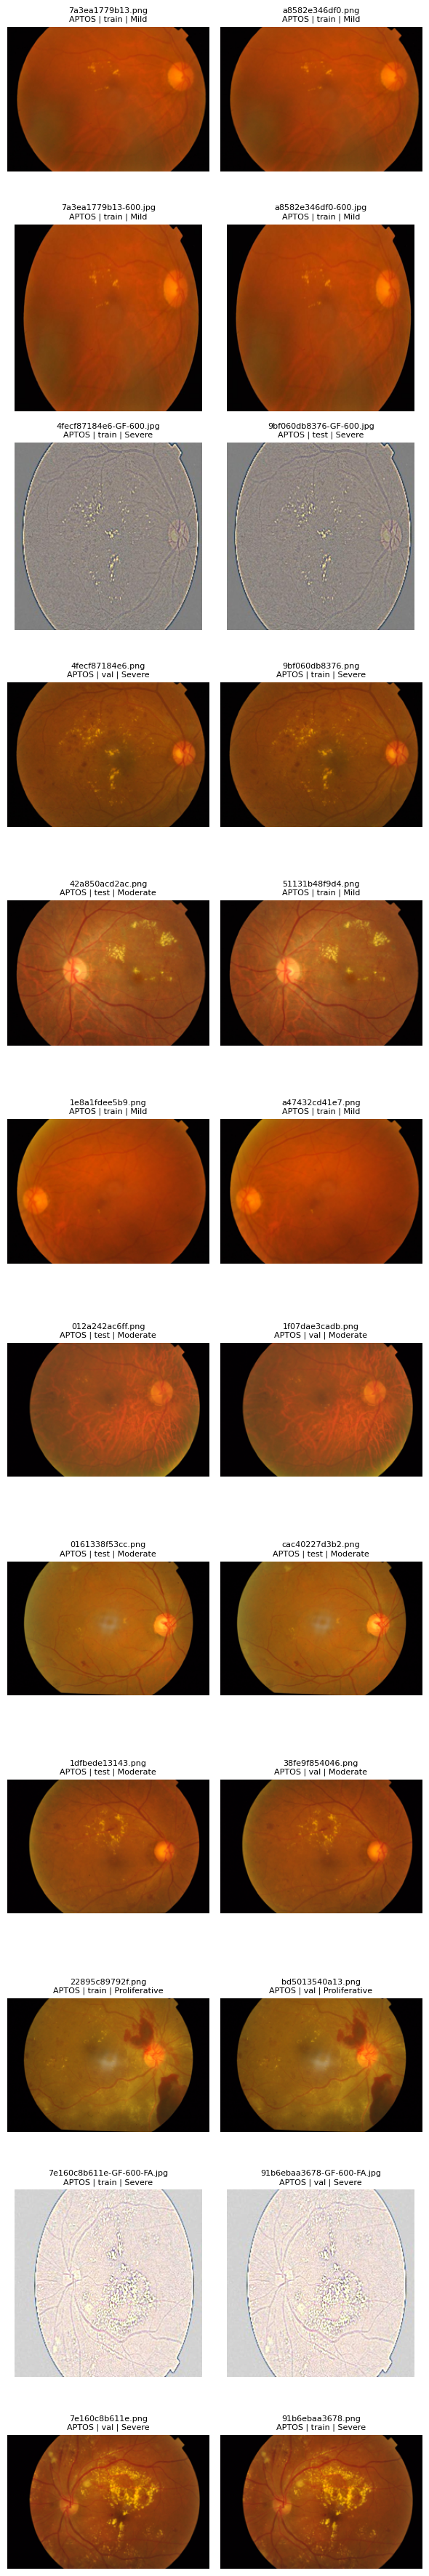

In [7]:
def identical_groups(d, key):
    multi = d[d.duplicated(key, keep=False)]
    join = lambda s: ', '.join(sorted(set(map(str, s))))
    g = multi.groupby(key).agg(files=('fname', 'size'), photos=('base_id', 'nunique'),
                               grades=('label', 'nunique'), sources=('source', join),
                               grade_list=('label', join), splits=('split', join),
                               names=('fname', lambda s: ' | '.join(sorted(s))))
    return g.sort_values(['photos', 'files'], ascending=False)

byte_groups = identical_groups(readable, 'md5')
pixel_groups = identical_groups(readable, 'pixel_md5')

idrid_ctrl = byte_groups[(byte_groups.sources == 'IDRiD') & (byte_groups.photos == 1) & (byte_groups.grades > 1)]
check('Control: IDRiD byte-identical conflicts', len(idrid_ctrl), EXPECTED['idrid_conflicts'])

cross = byte_groups[byte_groups.photos > 1].copy()
pix_only = pixel_groups[(pixel_groups.photos > 1) & ~pixel_groups.names.isin(byte_groups.names)]
sel = set(clean.fname)
cross['in_selection'] = cross.names.str.split(' | ', regex=False).apply(lambda ns: sum(n in sel for n in ns))
print(f'\nByte-identical file groups across different photo names: {len(cross)}')
print(f'Pixel-identical (but not byte-identical) groups across names: {len(pix_only)}')
print('Files per group:', cross.files.value_counts().sort_index().to_dict())
print('Groups by number of their files in the clean selection:', cross.in_selection.value_counts().sort_index().to_dict())
print('\nBy source combination:\n' + cross.sources.value_counts().to_string())
print('\nBy split combination:\n' + cross.splits.value_counts().to_string())
cross.to_csv(os.path.join(PROJECT_DIR, 'cross_name_identical.csv'))

# --- look at them
show = pd.concat([cross, pix_only]).head(12)
if len(show):
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for ax_row, (_, gr) in zip(axes, show.iterrows()):
        for ax, name in zip(ax_row, gr.names.split(' | ')[:2]):
            r = readable[readable.fname == name].iloc[0]
            im = Image.open(r.path).convert('RGB'); im.thumbnail((256, 256))
            ax.imshow(im); ax.axis('off')
            ax.set_title(f'{r.fname[:28]}\n{r.source} | {r.split} | {CLASS_NAMES[r.label]}', fontsize=8)
    plt.tight_layout(); plt.show()

## Step 6 · Duplicate photos, and what the duplicate policy removes
One photo usually has several files (`.png`, `-600`, `-GF`, flips…), so one duplicated photo appears in several file groups in Step 5. Here, photo IDs that share **any** identical file are joined into one **duplicate photo group**. The duplicate policy (D-012) is then **previewed** on the clean selection:
- same photo with different grades → drop all of its copies;
- same photo with the same grade → keep one (the original, then family A, then family B);
- any match with Messidor → remove it from the training pool.

The policy is **applied after the near-copy check** (D-014), together with the near copies it finds.

**Results**
- **135 duplicate photo groups** with 275 photo IDs: 131 pairs, 3 triples and 1 group of four. APTOS 123, DDR 9, Messidor-1 2, IDRiD 1.
- **31 groups have conflicting grades** (30 APTOS, 1 IDRiD); 9 of them differ by 2 grades or more. Our labels match APTOS's official `train.csv` 100%, so these conflicts are in APTOS's own labels.
- **Preview:** 167 photos removed (62 with conflicting grades, 105 extra copies). Base 20,145 → **19,978**: No DR 9,542 · Mild 1,975 · Moderate 5,216 · Severe 1,105 · PDR 2,140. Severe loses 16 photos.

In [8]:
# --- join photo IDs that share at least one identical file (union-find)
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

fname_to_base = dict(zip(readable.fname, readable.base_id))
for names in pd.concat([cross.names, pix_only.names]):
    ids = sorted({fname_to_base[n] for n in names.split(' | ')})
    for a, b in zip(ids, ids[1:]):
        parent[find(a)] = find(b)

dup = pd.DataFrame({'base_id': list(parent)})
dup['dup_group'] = dup.base_id.map(find)
photo_info = df.groupby('base_id').agg(source=('source', 'first'),
                                       grades=('label', lambda s: tuple(sorted(set(s)))))
dup = dup.join(photo_info, on='base_id')
g = dup.groupby('dup_group').agg(
    photos=('base_id', 'size'),
    source=('source', lambda s: ', '.join(sorted(set(s)))),
    grades=('grades', lambda s: tuple(sorted({x for t in s for x in t}))),
    ids=('base_id', lambda s: ' | '.join(sorted(s))))
g['conflict'] = g.grades.apply(len) > 1
g['spread'] = g.grades.apply(lambda t: max(t) - min(t))
dup.to_csv(os.path.join(PROJECT_DIR, 'duplicate_photo_groups.csv'), index=False)

print(f'Photo IDs involved: {len(dup):,}, in {len(g):,} duplicate photo groups')
print('Photos per group:', g.photos.value_counts().sort_index().to_dict())
print('\nGroups by source (columns: grades conflict?)\n' + pd.crosstab(g.source, g.conflict, margins=True).to_string())
print(f'\nConflicting groups: {int(g.conflict.sum())}, of which {int((g.spread >= 2).sum())} differ by 2 grades or more')
print('By grade combination:\n' + g[g.conflict].grades.value_counts().to_string())
print('\nAll conflicting groups:\n' + g[g.conflict][['source', 'grades', 'ids']].to_string(index=False))

# --- preview of the duplicate policy on the clean selection (applied after the near-copy check)
c2 = clean.merge(dup[['base_id', 'dup_group']], on='base_id', how='left')
c2['conflict'] = c2.dup_group.isin(g.index[g.conflict])
in_dup = c2.dup_group.notna()
same = c2[in_dup & ~c2.conflict].copy()
same['rank'] = same.family.map({'original': 0, 'A_geometry': 1, 'B_hue': 2})
same = same.sort_values(['dup_group', 'rank', 'base_id'])
drop_same = same[same.duplicated('dup_group')]              # keep one photo per same-grade group
removed = pd.concat([c2[c2.conflict].assign(why='conflicting grades → drop all'),
                     drop_same.assign(why='same grade → keep one')])
after = c2[~c2.base_id.isin(removed.base_id)]
base_after = int(after.family.isin(['original', 'A_geometry']).sum())
famb_after = int((after.family == 'B_hue').sum())
print(f'\nClean selection: {len(c2):,} photos, of which {int(in_dup.sum()):,} are in a duplicate group')
print('Photos the policy would remove, by reason, family and grade:')
print(pd.crosstab([removed.why, removed.family], removed.label, margins=True).rename(columns=CLASS_NAMES).to_string())
print(f'\nIf applied: base {base_after:,} (now {len(base):,}), family B {famb_after:,} (now {len(fam_b):,})')
print('Base dataset by grade after the preview:',
      after[after.family.isin(['original', 'A_geometry'])].label.map(CLASS_NAMES).value_counts()
      .reindex(CLASS_NAMES.values(), fill_value=0).to_dict())

Photo IDs involved: 275, in 135 duplicate photo groups
Photos per group: {2: 131, 3: 3, 4: 1}

Groups by source (columns: grades conflict?)
conflict    False  True  All
source                      
APTOS          93    30  123
DDR             9     0    9
IDRiD           0     1    1
Messidor-1      2     0    2
All           104    31  135

Conflicting groups: 31, of which 9 differ by 2 grades or more
By grade combination:
grades
(2, 3)    9
(2, 4)    8
(1, 2)    5
(0, 1)    4
(3, 4)    4
(1, 4)    1

All conflicting groups:
source grades                                        ids
 APTOS (1, 2)                1c4d87baaffc | 35aa7f5c2ec0
 APTOS (2, 3)                0cb14014117d | 4a44cc840ebe
 APTOS (0, 1)                42985aa2e32f | 6165081b9021
 APTOS (1, 4)                3ee4841936ef | 7005be54cab1
 APTOS (2, 3)                3cd801ffdbf0 | 7525ebb3434d
 APTOS (2, 3)                6253f23229b1 | 76cfe8967f7d
 APTOS (1, 2) 42a850acd2ac | 51131b48f9d4 | 8cb6b0efaaac
 APTOS (1, 2

## All checks
Every value expected from notebook 01, plus the APTOS check from Step 4, in one table. The two ⚠️ in Step 3 are expected: the exclusions explain them fully (the two ✅ checks right after them).

In [9]:
print(pd.DataFrame(CHECKS).to_string(index=False))

                                                          check   got  expected result
                                                          Files 45327     45327      ✅
                                      Distinct photos (base_id) 24916     24916      ✅
                                            Base dataset photos 20145     20150     ⚠️
                                         Family B add-on photos  3608      3605     ⚠️
                           Base photos if nothing were excluded 20150     20150      ✅
                       Family B photos if nothing were excluded  3605      3605      ✅
APTOS photos kept as a 600 px copy while the original is usable     0         0      ✅
                        Control: IDRiD byte-identical conflicts    22        22      ✅


## Conclusions and next steps
- **Every file opens.** 15 blank or nearly black files are excluded, and they explain the whole difference from notebook 01.
- **Model input at most 512 px** (D-013). The "~600 px" assumption in the docs is wrong, and the docs get the measured sizes.
- **APTOS:** the selection now always keeps the full-size original (D-007). The originals' size still differs between No DR and the other grades: a risk to check during training (D-013).
- **135 photos have duplicates under other names**, 31 with conflicting grades. The duplicate policy (D-012) removes 167 photos; base dataset **19,978** (preview).
- **Next:**
  1. **Near copies:** the same photo resized, re-compressed, flipped or recoloured under another name, and the same eye photographed twice. Built as tested code in `src/`, with the threshold chosen as fixed in D-014.
  2. **Apply the duplicate policy** to exact + near copies, in `src/`.
  3. **Image quality**, with criteria fixed first.
  4. **Update the docs**, then open the PR for issue #5.